# Case Study A — Exploratory Data Analysis

### ZeMA electromechanical cylinder dataset (Dorst et al. 2021), doi:10.5281/zenodo.5185953

This notebook explores the **raw input data** used by `case_study_A_analysis.py` — 11 sensor
channels × 4,766 run-to-failure cycles, each reading shipped with its own metrologically
evaluated standard uncertainty — before any modeling happens. It does **not** reproduce the
pipeline (MLP training, LPU/Monte Carlo propagation); see `case_study_A_analysis.py` and
`case_study_A_report.md` for that.

**Prerequisites**
- Run with the project's `zema_env` kernel (*Python (case_study_A - zema_env)*), the same
  environment used by the pipeline (`pip install -r requirements.txt`), plus `pandas` and
  `seaborn` for this notebook.
- The dataset HDF5 must already be downloaded/cached. The first `ZeMASamples(...)` call
  downloads ~2.67 GB from Zenodo if it isn't cached yet — see `README.md` §0–2.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))
from case_study_A_analysis import Config, load_zema  # reuse the pipeline's own loader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)


## 1. Load the dataset

Loads at the same resolution the pipeline uses (`Config` defaults: 4,766 cycles × 100
datapoints/sensor/cycle → 1,100 raw features per cycle). If a previous pipeline run already
populated the `pooch` cache, this is near-instant; otherwise it triggers the one-time Zenodo
download.


In [2]:
cfg = Config()
X, UX, y = load_zema(cfg)
print(f"X  (values):        {X.shape}")
print(f"UX (uncertainties): {UX.shape}")
print(f"y  (target):         {y.shape}, range [{y.min():.3f}, {y.max():.3f}]")


X  (values):        (4766, 1100)
UX (uncertainties): (4766, 1100)
y  (target):         (4766,), range [0.000, 1.000]


/Users/emanuelebuchicchio/repos/case_study_a/zema_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Channel layout

`X`/`UX` pack 11 sensor channels side by side, each occupying `cfg.datapoints_per_cycle` (100)
consecutive columns, in the order the ZeMA HDF5 stores them
(`zema_emc_annotated.dataset.ZEMA_QUANTITIES`, with `Acceleration` and `Motor_Current` expanded
over their 3 axes/phases).


In [3]:
CHANNEL_NAMES = [
    "Acceleration plain bearing", "Acceleration piston rod", "Acceleration ball bearing",
    "Active current", "Axial force",
    "Motor current phase 1", "Motor current phase 2", "Motor current phase 3",
    "Pneumatic pressure", "Sound pressure", "Velocity",
]
D = cfg.datapoints_per_cycle
assert len(CHANNEL_NAMES) * D == X.shape[1]


def channel_slice(i):
    return np.s_[:, i * D:(i + 1) * D]


for i, name in enumerate(CHANNEL_NAMES):
    print(f"{i:2d}  cols [{i * D:4d}:{(i + 1) * D:4d}]  {name}")


 0  cols [   0: 100]  Acceleration plain bearing
 1  cols [ 100: 200]  Acceleration piston rod
 2  cols [ 200: 300]  Acceleration ball bearing
 3  cols [ 300: 400]  Active current
 4  cols [ 400: 500]  Axial force
 5  cols [ 500: 600]  Motor current phase 1
 6  cols [ 600: 700]  Motor current phase 2
 7  cols [ 700: 800]  Motor current phase 3
 8  cols [ 800: 900]  Pneumatic pressure
 9  cols [ 900:1000]  Sound pressure
10  cols [1000:1100]  Velocity


## 3. Target variable `y`

`y_k = k / N` is the consumed-lifetime fraction, defined purely from the cycle index — not
measured — so by construction it is a perfect ramp from 0 to 1 and carries zero label
uncertainty. `RUL = 1 - y`. Plotted only to confirm the construction.


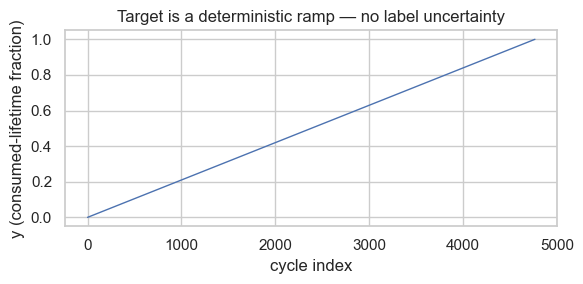

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(y, lw=1)
ax.set_xlabel("cycle index")
ax.set_ylabel("y (consumed-lifetime fraction)")
ax.set_title("Target is a deterministic ramp — no label uncertainty")
plt.tight_layout()
plt.show()


## 4. Per-channel value distributions

For each channel, collapse the 100 within-cycle readings to their per-cycle mean and look at the
distribution across the 4,766 cycles.


In [5]:
df_mean = pd.DataFrame(
    {name: X[channel_slice(i)].mean(axis=1) for i, name in enumerate(CHANNEL_NAMES)}
)
df_mean.describe().T


,count,mean,std,min,25%,50%,75%,max
Acceleration plain bearing,4766.0,0.1649,0.0842,-0.0705,0.1039,0.1541,0.2162,0.5481
Acceleration piston rod,4766.0,-0.6745,0.1783,-1.1478,-0.8076,-0.6983,-0.5645,0.1779
Acceleration ball bearing,4766.0,0.1149,0.1750,-3.4820,0.0187,0.1074,0.2110,3.7905
Active current,4766.0,-2.8879,0.0262,-3.3347,-2.9041,-2.8830,-2.8709,-2.8198
Axial force,4766.0,5.3454,0.0306,5.2266,5.3265,5.3516,5.3667,5.4338
Motor current phase 1,4766.0,0.0451,0.0174,-0.0040,0.0334,0.0430,0.0614,0.0838
Motor current phase 2,4766.0,-0.0266,0.0264,-0.0915,-0.0462,-0.0337,-0.0035,0.0584
Motor current phase 3,4766.0,0.0140,0.0199,-0.0250,-0.0038,0.0135,0.0312,0.0732
Pneumatic pressure,4766.0,832722.3146,1860.0271,827225.1591,831416.5233,832856.7918,834038.9180,836905.8573
Sound pressure,4766.0,-0.0958,0.0342,-0.2819,-0.1183,-0.0971,-0.0737,0.1046


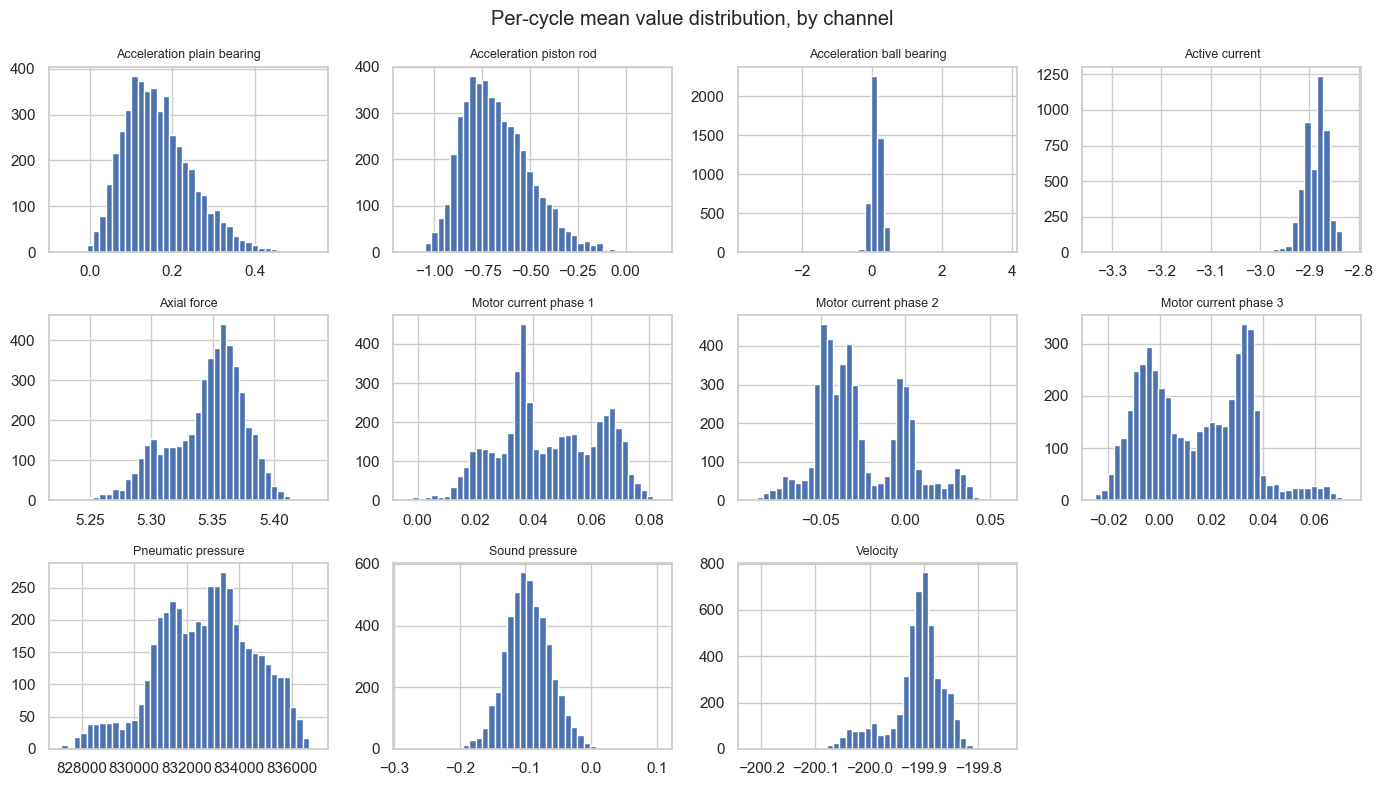

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, name in zip(axes.flat, CHANNEL_NAMES):
    ax.hist(df_mean[name], bins=40, color="#4C72B0")
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(CHANNEL_NAMES):]:
    ax.axis("off")
fig.suptitle("Per-cycle mean value distribution, by channel")
plt.tight_layout()
plt.show()


## 5. Per-channel uncertainty

**Key finding:** unlike the raw values, the standard uncertainty is **constant across every
cycle and every within-cycle reading** for 6 of the 11 channels (acceleration × 3 axes, axial
force, pneumatic pressure, sound pressure) — a single calibration-sheet value applied uniformly.
The other 5 channels (active current, the 3 motor-current phases, velocity) carry a per-sample
uncertainty that varies with the reading itself.


In [7]:
unc_summary = []
for i, name in enumerate(CHANNEL_NAMES):
    block = UX[channel_slice(i)]
    val_block = X[channel_slice(i)]
    n_unique = len(np.unique(np.round(block, 10)))
    rel = np.abs(block / np.where(val_block == 0, np.nan, val_block))
    unc_summary.append({
        "channel": name,
        "u constant?": "yes" if n_unique == 1 else "no",
        "u mean": block.mean(),
        "u min": block.min(),
        "u max": block.max(),
        "median |u/x|": np.nanmedian(rel),
    })
unc_df = pd.DataFrame(unc_summary).set_index("channel")
unc_df


,u constant?,u mean,u min,u max,median |u/x|
channel,,,,,
Acceleration plain bearing,yes,2.8319e+00,2.8319e+00,2.8319e+00,3.2803e+00
Acceleration piston rod,yes,2.8319e+00,2.8319e+00,2.8319e+00,7.7770e-01
Acceleration ball bearing,yes,2.8319e+00,2.8319e+00,2.8319e+00,1.0872e+00
Active current,no,2.8879e-02,1.2612e-02,3.9580e-02,1.0000e-02
Axial force,yes,1.2437e-02,1.2437e-02,1.2437e-02,2.3185e-03
Motor current phase 1,no,3.9629e-02,4.0416e-06,8.1029e-02,1.5000e-02
Motor current phase 2,no,3.9433e-02,4.4041e-08,8.0332e-02,1.5000e-02
Motor current phase 3,no,3.9087e-02,2.9153e-07,8.2582e-02,1.5000e-02
Pneumatic pressure,yes,1.6833e+04,1.6833e+04,1.6833e+04,2.0138e-02


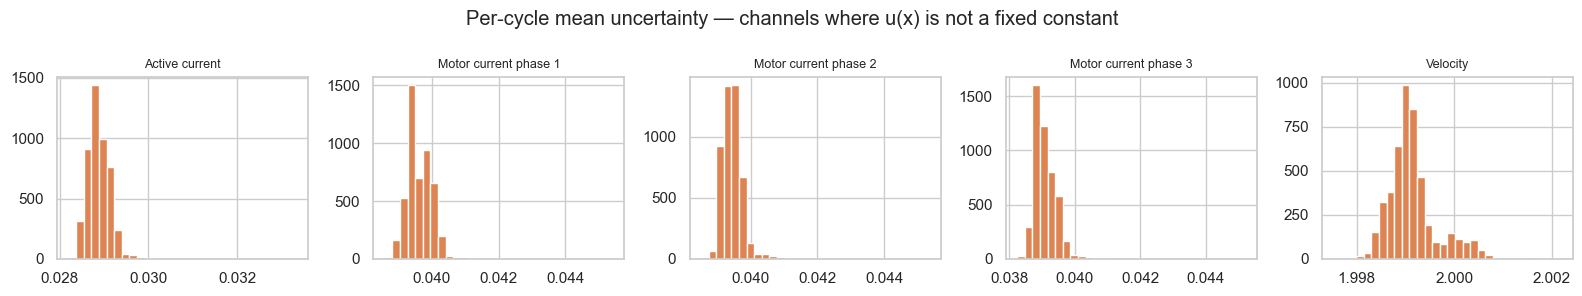

In [8]:
variable_channels = [n for n in CHANNEL_NAMES if unc_df.loc[n, "u constant?"] == "no"]
fig, axes = plt.subplots(1, len(variable_channels), figsize=(16, 3))
for ax, name in zip(axes, variable_channels):
    i = CHANNEL_NAMES.index(name)
    ax.hist(UX[channel_slice(i)].mean(axis=1), bins=30, color="#DD8452")
    ax.set_title(name, fontsize=9)
fig.suptitle("Per-cycle mean uncertainty — channels where u(x) is not a fixed constant")
plt.tight_layout()
plt.show()


## 6. Degradation trend: channel means vs. consumed lifetime

Since `y` is monotonic in cycle index, plotting each channel's per-cycle mean against `y` shows
which sensors trend with wear/degradation and which stay flat. Pearson correlation ranks the
channels.


In [9]:
corr = df_mean.corrwith(pd.Series(y)).sort_values(key=lambda s: s.abs(), ascending=False)
corr.to_frame("corr with y")


,corr with y
Motor current phase 3,0.7458
Motor current phase 2,-0.7387
Pneumatic pressure,-0.7297
Acceleration ball bearing,0.5407
Acceleration piston rod,0.5152
Sound pressure,-0.3014
Velocity,-0.2479
Motor current phase 1,-0.1801
Axial force,0.1801
Acceleration plain bearing,0.1200


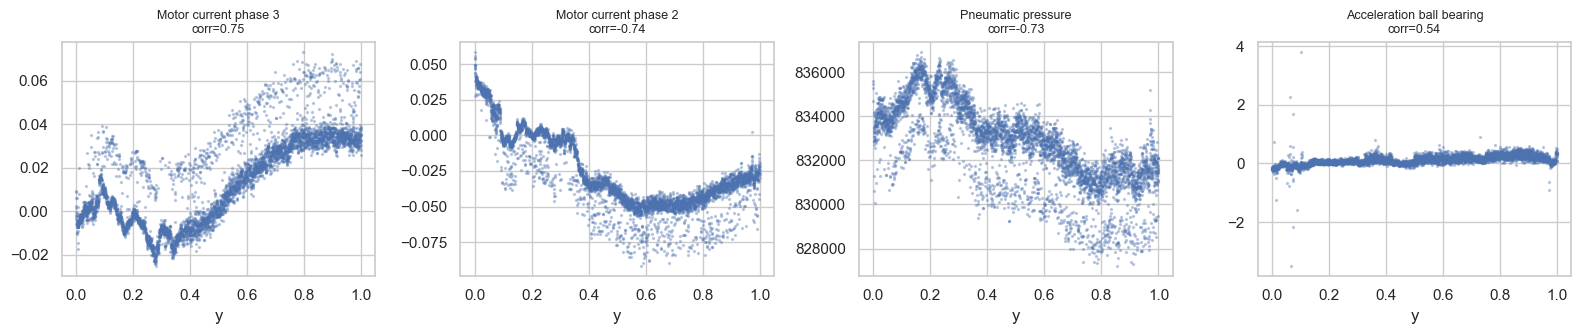

In [10]:
top = corr.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, top):
    ax.scatter(y, df_mean[name], s=2, alpha=0.3)
    ax.set_title(f"{name}\ncorr={corr[name]:.2f}", fontsize=9)
    ax.set_xlabel("y")
plt.tight_layout()
plt.show()


## 7. Example raw waveforms within a cycle

Beyond per-cycle summaries, each cycle carries 100 raw readings per channel. Comparing an early,
mid-life, and near-failure cycle's raw waveform shows shape changes that the per-cycle mean
alone can hide.


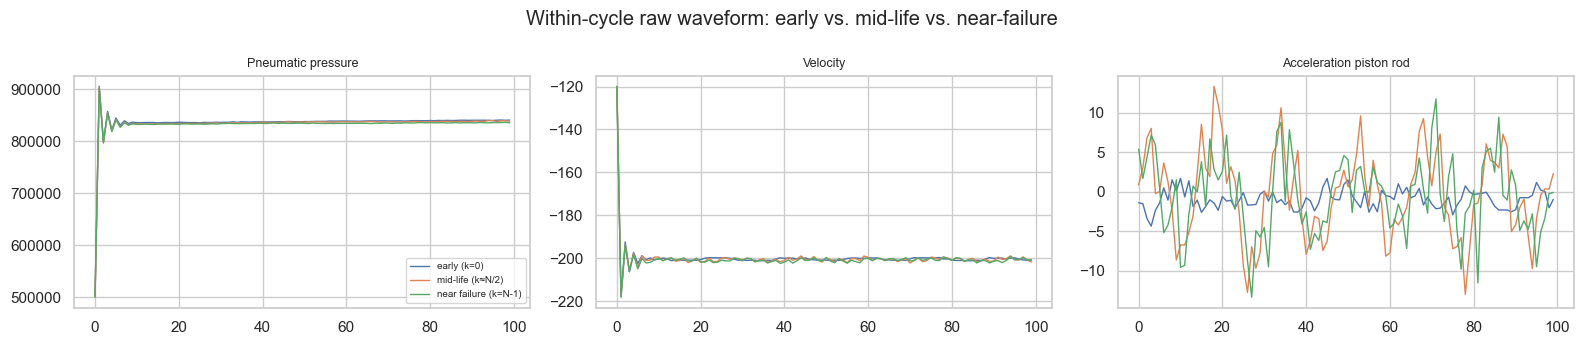

In [11]:
example_cycles = {
    "early (k=0)": 0,
    "mid-life (k≈N/2)": len(y) // 2,
    "near failure (k=N-1)": len(y) - 1,
}
plot_channels = ["Pneumatic pressure", "Velocity", "Acceleration piston rod"]

fig, axes = plt.subplots(1, len(plot_channels), figsize=(16, 3.5))
for ax, name in zip(axes, plot_channels):
    i = CHANNEL_NAMES.index(name)
    for label, k in example_cycles.items():
        ax.plot(X[k, i * D:(i + 1) * D], lw=1, label=label)
    ax.set_title(name, fontsize=9)
axes[0].legend(fontsize=7)
fig.suptitle("Within-cycle raw waveform: early vs. mid-life vs. near-failure")
plt.tight_layout()
plt.show()


## 8. Correlation across channels


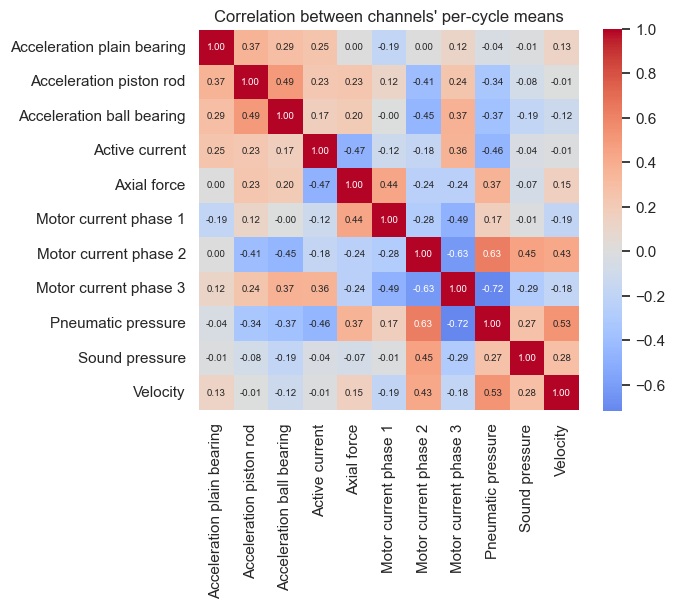

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    df_mean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
    square=True, ax=ax, annot_kws={"fontsize": 7},
)
ax.set_title("Correlation between channels' per-cycle means")
plt.tight_layout()
plt.show()


## 9. Sanity checks


In [13]:
print("NaNs in X:", np.isnan(X).sum(), " | NaNs in UX:", np.isnan(UX).sum())
print("Infs in X:", np.isinf(X).sum(), " | Infs in UX:", np.isinf(UX).sum())
zero_var = [name for name in CHANNEL_NAMES if df_mean[name].std() == 0]
print("Channels with zero variance across cycles:", zero_var or "none")


NaNs in X: 0  | NaNs in UX: 0
Infs in X: 0  | Infs in UX: 0
Channels with zero variance across cycles: none


## 10. Appendix — model output (`case_study_A_results.csv`)

Quick look at the pipeline's output artifact for continuity with the raw-data analysis above.
This is *not* a replacement for `make_validation_figure.py` (the paper's actual validation
figure) — just a sanity glance at the shape of the results.


In [14]:
results = pd.read_csv("case_study_A_results.csv")
results.columns = results.columns.str.lstrip("# ")
print(results.shape)
results.describe().T


(953, 7)


,count,mean,std,min,25%,50%,75%,max
y_true,953.0,0.5031,0.2911,0.0000,0.2558,0.4823,0.7650,0.9994
y_hat,953.0,0.4968,0.2932,-0.1303,0.2436,0.4722,0.7582,1.1274
u_physical_lpu,953.0,0.6413,0.1578,0.3355,0.5106,0.6116,0.7844,1.0779
u_physical_mc,953.0,0.9841,0.0826,0.7916,0.9216,0.9747,1.0575,1.1944
u_training,953.0,0.0493,0.0260,0.0157,0.0322,0.0416,0.0574,0.2138
u_c,953.0,0.6437,0.1579,0.3369,0.5132,0.6133,0.7856,1.0822
covered_k2,953.0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000


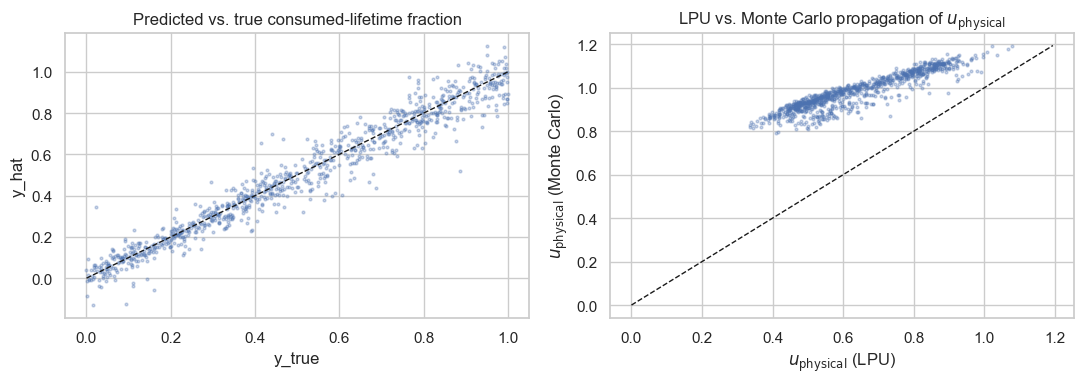

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(results["y_true"], results["y_hat"], s=4, alpha=0.3)
lims = [0, 1]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("y_true"); axes[0].set_ylabel("y_hat")
axes[0].set_title("Predicted vs. true consumed-lifetime fraction")

axes[1].scatter(results["u_physical_lpu"], results["u_physical_mc"], s=4, alpha=0.3)
lim = max(results["u_physical_lpu"].max(), results["u_physical_mc"].max())
axes[1].plot([0, lim], [0, lim], "k--", lw=1)
axes[1].set_xlabel(r"$u_{\mathrm{physical}}$ (LPU)"); axes[1].set_ylabel(r"$u_{\mathrm{physical}}$ (Monte Carlo)")
axes[1].set_title(r"LPU vs. Monte Carlo propagation of $u_{\mathrm{physical}}$")

plt.tight_layout()
plt.show()


## Summary

- **Shape**: 4,766 run-to-failure cycles × 11 sensor channels × 100 readings/cycle; no missing
  or infinite values; no zero-variance channels.
- **Target `y`** is a deterministic ramp (cycle index / N) — zero label uncertainty by
  construction.
- **Uncertainty structure**: 6 of 11 channels (acceleration × 3 axes, axial force, pneumatic
  pressure, sound pressure) carry a single, constant calibration uncertainty applied to every
  cycle and reading; the other 5 (active current, the 3 motor-current phases, velocity) carry a
  per-sample uncertainty that varies with the reading itself.
- **Degradation trend**: motor current (phases 2 and 3) and pneumatic pressure correlate most
  strongly with consumed-lifetime fraction (|corr| ≈ 0.73–0.75), followed by the ball-bearing and
  piston-rod accelerometers (≈ 0.52–0.54); active current and the plain-bearing accelerometer are
  nearly uncorrelated with wear. Within-cycle waveform *shape* (not just the mean) also visibly
  changes from early to near-failure cycles for pressure, velocity and acceleration.
- These are descriptive, raw-data statistics only. The trained-model *sensitivity* ranking
  reported in `case_study_A_report.md` §7/§9 (Pressure 51.8%, Velocity 25.2%, Acceleration-x
  11.5% of first-layer sensitivity) combines normalized uncertainty with the learned network
  weights, and is not simply reproduced from raw channel variance or correlation with `y`.
